# 03 — Leakage-free validation, effect of the engineered features, model comparison
**Competition:** [House Prices – Advanced Regression Techniques](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques)
**Author of this notebook:** Omisore Omolola Bimpe (team: Majba ull Alam Akash, Kofi Opoku Ayim, Omisore Omolola Bimpe)

**Why this notebook.** In `House_Price_2.ipynb` all preprocessing (filling missing values, Box-Cox, one-hot
encoding) is computed once on **train and test together**, and cross-validation is run afterwards. Statistics such as
the neighbourhood median of `LotFrontage` or the skewness of a column are then partly computed from the validation
rows, which is a (small) **leakage**: the validation score can be slightly optimistic.

Here the same preprocessing is rewritten as a function that is **fitted on the training part of each fold only** and
then applied to the validation part. With it we:
1. measure how much the leakage changes the CV score,
2. check the effect of each group of engineered features,
3. compare all models on exactly the same leakage-free validation.

Validation: 5-fold CV, `KFold(5, shuffle=True, random_state=42)`, RMSE on log(1 + SalePrice) — the competition metric.
The two known outliers (huge but cheap houses, see notebook 01) are removed from train first, as in Akash's notebook.

## 0. Setup and data


In [2]:
from pathlib import Path
if not (Path("train.csv").exists() and Path("test.csv").exists()):
    try:
        from google.colab import files
        files.upload()          # choose train.csv and test.csv
    except ImportError:
        print("Put train.csv and test.csv next to this notebook.")
print(sorted(p.name for p in Path(".").glob("*.csv")))

['test.csv', 'train.csv']


In [3]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import skew
from scipy.special import boxcox1p
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import Lasso, ElasticNet, Ridge
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.svm import SVR
warnings.filterwarnings("ignore")

SEED = 42
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
train = train[~((train["GrLivArea"] > 4000) & (train["SalePrice"] < 300000))].reset_index(drop=True)
y = np.log1p(train["SalePrice"].to_numpy())
kf = KFold(5, shuffle=True, random_state=SEED)
print(f"train after removing outliers: {len(train)} houses | test: {len(test)} houses")

train after removing outliers: 1458 houses | test: 1459 houses


## 1. Preprocessing as a function: fitted on one part, applied to another
Same steps as in `House_Price_2.ipynb`. Everything that *learns* from the data is computed from `fit_df` only:
neighbourhood medians, most frequent values, which columns are skewed, and the list of one-hot columns.

In [4]:
NONE_COLS = ["Alley", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2", "FireplaceQu",
             "GarageType", "GarageFinish", "GarageQual", "GarageCond", "PoolQC", "Fence", "MiscFeature", "MasVnrType"]
ZERO_COLS = ["GarageYrBlt", "GarageArea", "GarageCars", "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF",
             "BsmtFullBath", "BsmtHalfBath", "MasVnrArea"]
MODE_COLS = ["MSZoning", "Electrical", "KitchenQual", "Exterior1st", "Exterior2nd", "SaleType"]
QUAL = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
FIN = {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6}
FEATURE_GROUPS = {
    "totals": ["TotalSF", "TotalBath", "TotalPorchSF"],
    "age": ["HouseAge", "RemodAge", "WasRemodeled", "IsNew"],
    "flags": ["HasPool", "HasGarage", "HasBsmt", "HasFireplace", "Has2ndFloor"],
    "interactions": ["QualSF", "QualGrLiv"],
}
ALL_GROUPS = tuple(FEATURE_GROUPS)

def clean(df):
    """Steps that use no statistics (the same result whatever data they are fitted on)."""
    df = df.drop(columns=[c for c in ["Id", "SalePrice", "Utilities"] if c in df]).copy()
    df[NONE_COLS] = df[NONE_COLS].fillna("None")
    df[ZERO_COLS] = df[ZERO_COLS].fillna(0)
    df["Functional"] = df["Functional"].fillna("Typ")
    for c in ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC", "KitchenQual", "FireplaceQu",
              "GarageQual", "GarageCond", "PoolQC"]:
        df[c] = df[c].map(QUAL)            # NaN stays NaN for now (KitchenQual is filled by the mode later)
    df["BsmtExposure"] = df["BsmtExposure"].map({"None": 0, "No": 1, "Mn": 2, "Av": 3, "Gd": 4}).fillna(0)
    df["BsmtFinType1"] = df["BsmtFinType1"].map(FIN).fillna(0)
    df["BsmtFinType2"] = df["BsmtFinType2"].map(FIN).fillna(0)
    df["GarageFinish"] = df["GarageFinish"].map({"None": 0, "Unf": 1, "RFn": 2, "Fin": 3}).fillna(0)
    return df

def add_features(df, groups):
    yr = df["YrSold"].astype(int)
    new = {
        "TotalSF": df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"],
        "TotalBath": df["FullBath"] + 0.5 * df["HalfBath"] + df["BsmtFullBath"] + 0.5 * df["BsmtHalfBath"],
        "TotalPorchSF": df["OpenPorchSF"] + df["EnclosedPorch"] + df["3SsnPorch"] + df["ScreenPorch"] + df["WoodDeckSF"],
        "HouseAge": yr - df["YearBuilt"], "RemodAge": yr - df["YearRemodAdd"],
        "WasRemodeled": (df["YearRemodAdd"] != df["YearBuilt"]).astype(int), "IsNew": (yr == df["YearBuilt"]).astype(int),
        "HasPool": (df["PoolArea"] > 0).astype(int), "HasGarage": (df["GarageArea"] > 0).astype(int),
        "HasBsmt": (df["TotalBsmtSF"] > 0).astype(int), "HasFireplace": (df["Fireplaces"] > 0).astype(int),
        "Has2ndFloor": (df["2ndFlrSF"] > 0).astype(int),
    }
    new["QualSF"] = df["OverallQual"] * new["TotalSF"]
    new["QualGrLiv"] = df["OverallQual"] * df["GrLivArea"]
    for g in groups:
        for c in FEATURE_GROUPS[g]:
            df[c] = new[c]
    return df

def preprocess(fit_df, apply_df, groups=ALL_GROUPS, min_unique=5):
    """Learn all statistics on fit_df, transform fit_df and apply_df. Returns two numpy matrices.
    min_unique: a skewed column is Box-Cox transformed only if it has more than min_unique distinct values
    (5 = rule from House_Price_2.ipynb, 2 = only 0/1 flags are skipped; see section 3b)."""
    a, b = clean(fit_df), clean(apply_df)
    # LotFrontage: neighbourhood median learned on fit_df
    med_n = a.groupby("Neighborhood")["LotFrontage"].median()
    med_all = a["LotFrontage"].median()
    for d in (a, b):
        d["LotFrontage"] = d["LotFrontage"].fillna(d["Neighborhood"].map(med_n)).fillna(med_all)
    # most frequent values learned on fit_df
    for c in MODE_COLS:
        m = a[c].mode()[0]
        a[c], b[c] = a[c].fillna(m), b[c].fillna(m)
    for d in (a, b):
        for c in ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC", "KitchenQual", "FireplaceQu",
                  "GarageQual", "GarageCond", "PoolQC"]:
            d[c] = d[c].fillna(0)
    a, b = add_features(a, groups), add_features(b, groups)
    for d in (a, b):
        for c in ["MSSubClass", "MoSold", "YrSold"]:
            d[c] = d[c].astype(str)
    # skewed columns chosen on fit_df
    num = a.select_dtypes(include=np.number).columns
    sk = a[num].apply(lambda s: skew(s.dropna()))
    skewed = [c for c in sk[abs(sk) > 0.75].index if a[c].nunique() > min_unique]
    for d in (a, b):
        d[skewed] = boxcox1p(d[skewed].clip(lower=0), 0.15)
    # one-hot columns defined by fit_df; categories unseen in fit_df become all-zero
    a = pd.get_dummies(a, dtype=float)
    b = pd.get_dummies(b, dtype=float).reindex(columns=a.columns, fill_value=0.0)
    return a.fillna(0).to_numpy(), b.fillna(0).to_numpy()

Xa, Xb = preprocess(train, test)
print(f"features: {Xa.shape[1]} | train {Xa.shape} | test {Xb.shape}")

features: 283 | train (1458, 283) | test (1459, 283)


## 2. Models (same settings as in `House_Price_2.ipynb`)

In [5]:
def make_models(fast=False):
    m = {
        "Ridge": make_pipeline(RobustScaler(), Ridge(alpha=15)),
        "Lasso": make_pipeline(RobustScaler(), Lasso(alpha=0.0005, max_iter=50000)),
        "ElasticNet": make_pipeline(RobustScaler(), ElasticNet(alpha=0.0005, l1_ratio=0.9, max_iter=50000)),
        "SVR": make_pipeline(RobustScaler(), SVR(C=20, epsilon=0.008, gamma=0.0005)),
    }
    if not fast:
        m["GradientBoosting"] = GradientBoostingRegressor(n_estimators=3000, learning_rate=0.02, max_depth=4,
            max_features="sqrt", min_samples_leaf=15, min_samples_split=10, loss="huber", subsample=0.8,
            random_state=SEED)
        try:
            from xgboost import XGBRegressor
            m["XGBoost"] = XGBRegressor(n_estimators=2500, learning_rate=0.01, max_depth=3, subsample=0.6,
                colsample_bytree=0.4, min_child_weight=2, reg_alpha=0.001, reg_lambda=0.8,
                random_state=SEED, n_jobs=-1)
        except ImportError:
            print("xgboost not installed - XGBoost skipped")
    return m

def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

def cv_leakage_free(models, groups=ALL_GROUPS, min_unique=2):
    """Preprocessing is fitted inside every fold. Returns out-of-fold predictions per model."""
    oof = {name: np.zeros(len(y)) for name in models}
    for tr_idx, va_idx in kf.split(train):
        Xtr, Xva = preprocess(train.iloc[tr_idx], train.iloc[va_idx], groups, min_unique)
        for name, m in models.items():
            oof[name][va_idx] = clone(m).fit(Xtr, y[tr_idx]).predict(Xva)
    return oof

def cv_combined(models):
    """As in House_Price_2.ipynb: preprocessing fitted once on train + test, then CV."""
    X_all, _ = preprocess(pd.concat([train, test], ignore_index=True), test)
    X = X_all[:len(train)]
    oof = {name: np.zeros(len(y)) for name in models}
    for tr_idx, va_idx in kf.split(X):
        for name, m in models.items():
            oof[name][va_idx] = clone(m).fit(X[tr_idx], y[tr_idx]).predict(X[va_idx])
    return oof

def fold_scores(pred):
    return [rmse(pred[va], y[va]) for _, va in kf.split(train)]

## 3. Does the leakage change the score?
The fast models (Ridge, Lasso, ElasticNet, SVR) are scored with both schemes on the same folds.

In [6]:
t = time.time()
fast = make_models(fast=True)
oof_comb, oof_free = cv_combined(fast), cv_leakage_free(fast, min_unique=5)
leak = pd.DataFrame({
    "combined preprocessing (House_Price_2)": {n: np.mean(fold_scores(oof_comb[n])) for n in fast},
    "leakage-free (fitted per fold)": {n: np.mean(fold_scores(oof_free[n])) for n in fast},
})
leak["difference"] = leak.iloc[:, 1] - leak.iloc[:, 0]
leak = leak.round(5)
leak.to_csv("leakage_comparison.csv")
print(f"{time.time() - t:.0f}s")
leak

17s


,combined preprocessing (House_Price_2),leakage-free (fitted per fold),difference
Ridge,0.11342,0.11308,-0.00034
Lasso,0.11176,0.11144,-0.00031
ElasticNet,0.11187,0.11157,-0.00031
SVR,0.11042,0.12171,0.01129


**Findings.** For the linear models the leakage makes almost no difference: with preprocessing fitted per fold, Ridge,
Lasso and ElasticNet change by only about 0.0003 (0.1118 → 0.1114 for Lasso), which is much smaller than the differences
between the models themselves (Lasso 0.1118 vs Ridge 0.1134) and far below the standard deviation over folds (≈ 0.007).
Information could leak through the neighbourhood medians of `LotFrontage`, the most frequent values used for filling,
the choice of Box-Cox columns and the list of one-hot columns, because all of them were computed on train and test
together. The leakage-free score is the more honest estimate for the Kaggle test set, because there the model also has to
work with statistics learned only from the training houses. SVR, however, gets clearly worse (0.1104 → 0.1217); this is
not caused by leakage but by a fragile preprocessing rule, explained in 3b.

### 3b. Why does SVR get so much worse?
The linear models hardly change, but SVR gets clearly worse with per-fold preprocessing. Looking at the error per fold
and the worst-predicted house in each fold:

In [7]:
svr = make_models(fast=True)["SVR"]
rows = []
for i, (tr_idx, va_idx) in enumerate(kf.split(train)):
    pred = oof_free["SVR"][va_idx]
    err = np.abs(pred - y[va_idx]); j = np.argmax(err)
    house = train.iloc[va_idx].iloc[j]
    pool_values = train.iloc[tr_idx]["PoolArea"].nunique()
    rows.append({"fold": i, "RMSE combined": rmse(oof_comb["SVR"][va_idx], y[va_idx]),
                 "RMSE per fold": rmse(pred, y[va_idx]), "worst house Id": int(house["Id"]),
                 "its PoolArea": int(house["PoolArea"]), "its error": err[j],
                 "distinct PoolArea values in fold-train": pool_values})
pd.DataFrame(rows).round(4)

,fold,RMSE combined,RMSE per fold,worst house Id,its PoolArea,its error,distinct PoolArea values in fold-train
0,0,0.1175,0.1175,31,0,0.9107,6
1,1,0.1086,0.1367,1183,555,1.3592,5
2,2,0.1120,0.1121,633,0,0.7421,7
3,3,0.1190,0.1190,496,0,0.7513,7
4,4,0.0950,0.1233,1387,519,0.9790,4


**Cause.** The Box-Cox rule from `House_Price_2.ipynb` only transforms a skewed column if it has **more than 5 distinct
values**. Only a handful of houses have a pool, so in some folds `PoolArea` has ≤ 5 distinct values in the training part
and is **not** transformed. Its raw value (several hundred sq ft) then goes to `RobustScaler`, which divides by the
inter-quartile range — but for `PoolArea` that range is 0 (almost all houses have no pool), so the value is not scaled
at all. For the RBF kernel of SVR a pool house then looks infinitely far away from every other house, and its prediction
collapses. The linear models are not affected because they simply give `PoolArea` a small coefficient.

**Fix.** Skip only true 0/1 flags (`min_unique=2`) instead of every column with ≤ 5 values, so `PoolArea` is always
transformed. This choice does not depend on the fold. All following sections use the fixed rule.

In [8]:
oof_fix = cv_leakage_free(fast, min_unique=2)
leak["leakage-free + fixed Box-Cox rule"] = [np.mean(fold_scores(oof_fix[n])) for n in leak.index]
leak = leak.round(5)
leak.to_csv("leakage_comparison.csv")
leak

,combined preprocessing (House_Price_2),leakage-free (fitted per fold),difference,leakage-free + fixed Box-Cox rule
Ridge,0.11342,0.11308,-0.00034,0.11330
Lasso,0.11176,0.11144,-0.00031,0.11185
ElasticNet,0.11187,0.11157,-0.00031,0.11192
SVR,0.11042,0.12171,0.01129,0.11034


**Findings.** In folds 1 and 4 the worst houses are Id 1183 and Id 1387, both with a pool (555 and 519 sq ft). Their
errors are 1.36 and 0.98 on the log scale, while with the combined preprocessing they are predicted well. In exactly these
folds `PoolArea` has only 5 and 4 distinct values in the training part, so the "more than 5 distinct values" rule skips
the Box-Cox transform, and the raw pool area is not scaled by `RobustScaler` (its inter-quartile range is 0). With the
fixed rule (skip only 0/1 flags), SVR goes back to 0.1103, as good as before, and the linear models change by less than
0.0005. The lesson: a rule that depends on the data (here the number of distinct values) can behave differently on
different subsets of the data, so preprocessing should be checked fold by fold, not only on the full training set.

## 4. Effect of the engineered features
Akash's notebook adds 14 new features in 4 groups. Using the leakage-free CV and two different models (Lasso, SVR),
we compare: no new features, all new features, and all minus one group at a time.

In [9]:
for g, cols in FEATURE_GROUPS.items():
    print(f"{g:13s}: {', '.join(cols)}")

totals       : TotalSF, TotalBath, TotalPorchSF
age          : HouseAge, RemodAge, WasRemodeled, IsNew
flags        : HasPool, HasGarage, HasBsmt, HasFireplace, Has2ndFloor
interactions : QualSF, QualGrLiv


In [10]:
t = time.time()
models_fe = {k: v for k, v in make_models(fast=True).items() if k in ("Lasso", "SVR")}
runs = {"no new features": (), "all new features": ALL_GROUPS}
for g in ALL_GROUPS:
    runs[f"all − {g}"] = tuple(x for x in ALL_GROUPS if x != g)
rows = []
for label, groups in runs.items():
    oof = cv_leakage_free(models_fe, groups)
    rows.append({"features": label, **{n: np.mean(fold_scores(oof[n])) for n in models_fe}})
fe = pd.DataFrame(rows).set_index("features").round(5)
fe["Δ Lasso vs all"] = (fe["Lasso"] - fe.loc["all new features", "Lasso"]).round(5)
fe["Δ SVR vs all"] = (fe["SVR"] - fe.loc["all new features", "SVR"]).round(5)
fe.to_csv("feature_effect.csv")
print(f"{time.time() - t:.0f}s")
fe

28s


,Lasso,SVR,Δ Lasso vs all,Δ SVR vs all
features,,,,
no new features,0.11209,0.11159,0.00024,0.00125
all new features,0.11185,0.11034,0.00000,0.00000
all − totals,0.11219,0.11104,0.00034,0.00070
all − age,0.11186,0.11047,0.00001,0.00013
all − flags,0.11184,0.11041,-0.00001,0.00007
all − interactions,0.11175,0.11034,-0.00010,0.00000


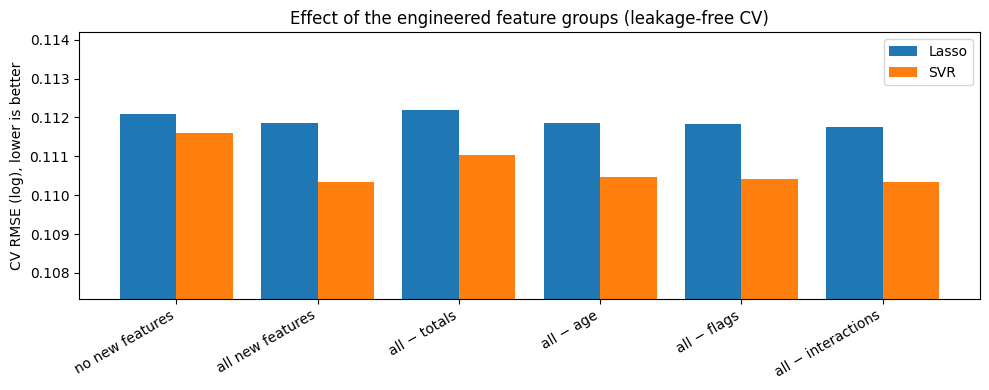

In [11]:
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(fe))
ax.bar(x - 0.2, fe["Lasso"], 0.4, label="Lasso")
ax.bar(x + 0.2, fe["SVR"], 0.4, label="SVR")
ax.set_xticks(x); ax.set_xticklabels(fe.index, rotation=30, ha="right")
ax.set(ylabel="CV RMSE (log), lower is better", title="Effect of the engineered feature groups (leakage-free CV)",
       ylim=(fe[["Lasso", "SVR"]].min().min() - 0.003, fe[["Lasso", "SVR"]].max().max() + 0.002))
ax.legend()
fig.tight_layout(); fig.savefig(FIG / "03_feature_effect.png", dpi=150); plt.show()

**Findings.** The engineered features help both models: without them the CV RMSE is 0.1121 (Lasso) and 0.1116 (SVR),
with them 0.1119 and 0.1103. The **totals** group (TotalSF, TotalBath, TotalPorchSF) is the most useful: removing it
makes Lasso worse by 0.0003 and SVR by 0.0007. The age and flag groups add only very little (at most about 0.0001
for either model). The **interactions** (QualSF, QualGrLiv) are not useful: removing them even improves Lasso
slightly (−0.0001) and does not change SVR. Lasso and SVR agree on the ranking of the groups. All effects are small
compared with the variation between folds, so the main conclusion is that total area is the one engineered idea that
clearly matters.

## 5. Comparison of all models on the same leakage-free validation
All models, plus the stacking blend with the weights found in `House_Price_2.ipynb`
(Lasso 0.187, SVR 0.393, GradientBoosting 0.135, XGBoost 0.285). The baselines use the same folds.
Takes a few minutes (gradient boosting and XGBoost are slow).

In [12]:
t = time.time()
models = make_models()
oof = cv_leakage_free(models)
# baselines on the same folds
oof["constant (mean log price)"] = np.zeros(len(y))
oof["rule: median by OverallQual"] = np.zeros(len(y))
for tr_idx, va_idx in kf.split(train):
    oof["constant (mean log price)"][va_idx] = y[tr_idx].mean()
    med = pd.Series(y[tr_idx]).groupby(train["OverallQual"].iloc[tr_idx].to_numpy()).median()
    oof["rule: median by OverallQual"][va_idx] = train["OverallQual"].iloc[va_idx].map(med).fillna(np.median(y[tr_idx])).to_numpy()
w = {"Lasso": 0.187, "SVR": 0.393, "GradientBoosting": 0.135, "XGBoost": 0.285}
w = {k: v for k, v in w.items() if k in oof}
oof["stacking blend (weights from House_Price_2)"] = sum(v * oof[k] for k, v in w.items()) / sum(w.values())
comparison = pd.DataFrame({
    "CV RMSE (log)": {n: np.mean(fold_scores(p)) for n, p in oof.items()},
    "std over folds": {n: np.std(fold_scores(p)) for n, p in oof.items()},
}).sort_values("CV RMSE (log)", ascending=False).round(5)
comparison.to_csv("model_comparison.csv")
print(f"{time.time() - t:.0f}s")
comparison

106s


,CV RMSE (log),std over folds
constant (mean log price),0.39928,0.01681
rule: median by OverallQual,0.22865,0.00856
Ridge,0.11330,0.00831
ElasticNet,0.11192,0.00695
Lasso,0.11185,0.00692
XGBoost,0.11156,0.00578
GradientBoosting,0.11153,0.00863
SVR,0.11034,0.00863
stacking blend (weights from House_Price_2),0.10583,0.00783


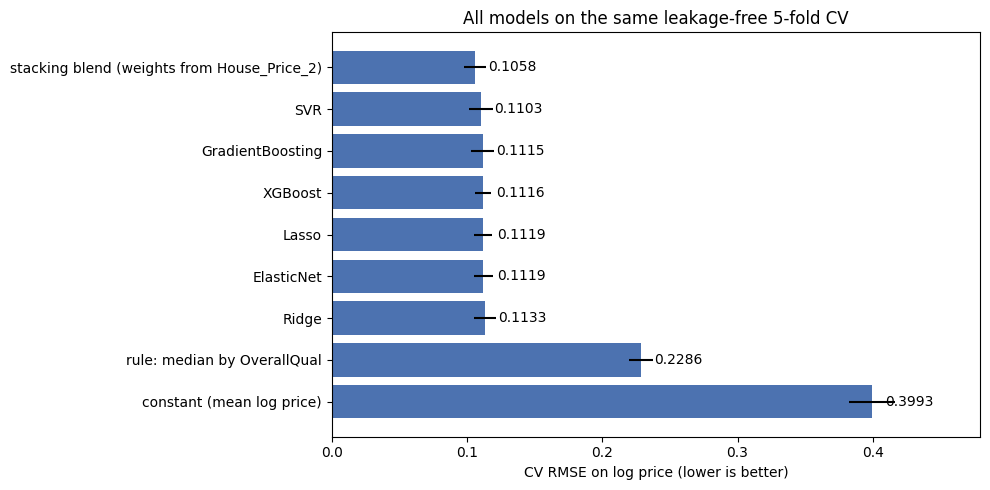

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(comparison.index, comparison["CV RMSE (log)"], xerr=comparison["std over folds"], color="#4C72B0")
for i, v in enumerate(comparison["CV RMSE (log)"]):
    ax.text(v + 0.01, i, f"{v:.4f}", va="center")
ax.set(xlabel="CV RMSE on log price (lower is better)", title="All models on the same leakage-free 5-fold CV",
       xlim=(0, comparison["CV RMSE (log)"].max() + 0.08))
fig.tight_layout(); fig.savefig(FIG / "03_model_comparison.png", dpi=150); plt.show()

Note: the blend weights were chosen by Akash on the same training data, so the blend score is slightly optimistic.

**Findings.** On the same leakage-free validation the best single model is SVR (0.1103), followed by gradient boosting
(0.1115), XGBoost (0.1116), Lasso (0.1119), ElasticNet (0.1119) and Ridge (0.1133). The differences between these models
(≤ 0.003) are smaller than the standard deviation over folds (0.006–0.009), so they are not clearly different from each
other. The stacking blend reaches 0.1058, about 0.0045 better than the best single model: linear models, a kernel
model and tree ensembles make different kinds of errors, and averaging them cancels part of the errors. The blend score
is slightly optimistic because its weights were chosen on the same training data. Compared with the constant baseline
(0.3993) and the best simple rule (0.2287), all models reduce the error by a factor of about 2 to 4.

## 6. Summary
* **Leakage:** fitting the preprocessing on train + test together changes the score of the linear models by only
  about 0.0003, so the earlier CV results are reliable for them.
* **Fragile rule found and fixed:** the "more than 5 distinct values" Box-Cox rule left `PoolArea` untransformed in two
  folds, which broke SVR for houses with a pool (0.1217); with the fixed rule SVR is back at 0.1103.
* **Features:** the engineered features help a little overall; total area (TotalSF, TotalBath, TotalPorchSF) helps most,
  the interaction features do not help.
* **Models:** SVR is the best single model (0.1103); the stacking blend of Lasso, SVR, gradient boosting and XGBoost
  reaches 0.1058, compared with 0.3993 for the constant baseline and 0.2287 for the best simple rule.